# Notebook 04: modelado supervisado, SHAP y análisis temporal

*Usar IA sin estar convencido: discrepancia entre uso y actitud en desarrolladores de software.* Trabajo final de especialización, Maestría en Explotación de Datos y Descubrimiento del Conocimiento, FCEyN-UBA.

Entrena cuatro modelos sobre los usuarios de IA (80.369 filas y 98 variables predictoras) con validación cruzada estratificada de 5 partes, calcula los valores SHAP de un random forest, relaciona las variables con las dimensiones de Wang et al. (2024) y estudia cómo cambia el fenómeno entre 2023 y 2025.

La lógica está en `scripts/modelado.py`, `scripts/decision_drop_auc.py`, `scripts/temporal.py` y `scripts/modelado_temporal.py`.

## 1. Preparación

In [1]:
import sys
import importlib.util
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

modelado = load_module("modelado", ROOT / "scripts" / "modelado.py")
auc_decision = load_module("auc_decision", ROOT / "scripts" / "decision_drop_auc.py")

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"Etiquetas de la variable a predecir: {modelado.TARGET_LABELS}")

Etiquetas de la variable a predecir: {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}


## 2. Carga de los datos

In [2]:
df = modelado.cargar_dataset()
X, y, feature_cols = modelado.preparar_features(df)
print(f"\nVariables: {len(feature_cols)}  ·  Filas: {len(X):,}  ·  Prevalencia sin discrepancia: {y.mean():.1%}")

Dataset: 80,369 filas, 99 columnas
  target=1 (Sin discrepancia): 78.5%
  target=0 (Con discrepancia uso-actitud): 21.5%
Variables: 98, filas: 80,369

Variables: 98  ·  Filas: 80,369  ·  Prevalencia sin discrepancia: 78.5%


## 3. Los cuatro modelos

In [3]:
models = modelado.definir_modelos(y)
list(models.keys())

scale_pos_weight (XGBoost) = 0.274


['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']

## 4. Validación cruzada estratificada de 5 partes

In [4]:
cv_results, cv = modelado.evaluar_cv(models, X, y)

resumen = pd.DataFrame(cv_results).T.sort_values("ROC-AUC", ascending=False)
resumen_display = pd.DataFrame(index=resumen.index)
resumen_display["ROC-AUC"] = resumen.apply(lambda r: f"{r['ROC-AUC']:.4f} ± {r['ROC-AUC_std']:.4f}", axis=1)
resumen_display["F1-macro"] = resumen.apply(lambda r: f"{r['F1-macro']:.4f} ± {r['F1-macro_std']:.4f}", axis=1)
resumen_display.index.name = "Modelo"
resumen_display

  Logistic Regression... 

ROC-AUC=0.6320 ± 0.0058  F1=0.5418 ± 0.0027
  Decision Tree... 

ROC-AUC=0.6097 ± 0.0053  F1=0.5162 ± 0.0060
  Random Forest... 

ROC-AUC=0.6321 ± 0.0066  F1=0.5713 ± 0.0049
  XGBoost... 

ROC-AUC=0.6312 ± 0.0060  F1=0.5493 ± 0.0037


,ROC-AUC,F1-macro
Modelo,,
Random Forest,0.6321 ± 0.0066,0.5713 ± 0.0049
Logistic Regression,0.6320 ± 0.0058,0.5418 ± 0.0027
XGBoost,0.6312 ± 0.0060,0.5493 ± 0.0037
Decision Tree,0.6097 ± 0.0053,0.5162 ± 0.0060


**Lectura.** Los tres primeros modelos quedan alrededor de 0,63 de ROC-AUC. Sus diferencias, de 0,001 o menos, son mucho menores que la variación entre partes (±0,006), así que no se elige un ganador. El árbol de decisión queda por debajo. Los parámetros se fijaron a mano, sin búsqueda de hiperparámetros, por lo que el AUC es un piso.

## 5. Curvas ROC con predicciones fuera de muestra

  Predicciones fuera de muestra, Logistic Regression... 

AUC=0.6319
  Predicciones fuera de muestra, Decision Tree... 

AUC=0.6098
  Predicciones fuera de muestra, Random Forest... 

AUC=0.6320
  Predicciones fuera de muestra, XGBoost... 

AUC=0.6311
Guardado outputs/modelos_curvas_roc.png


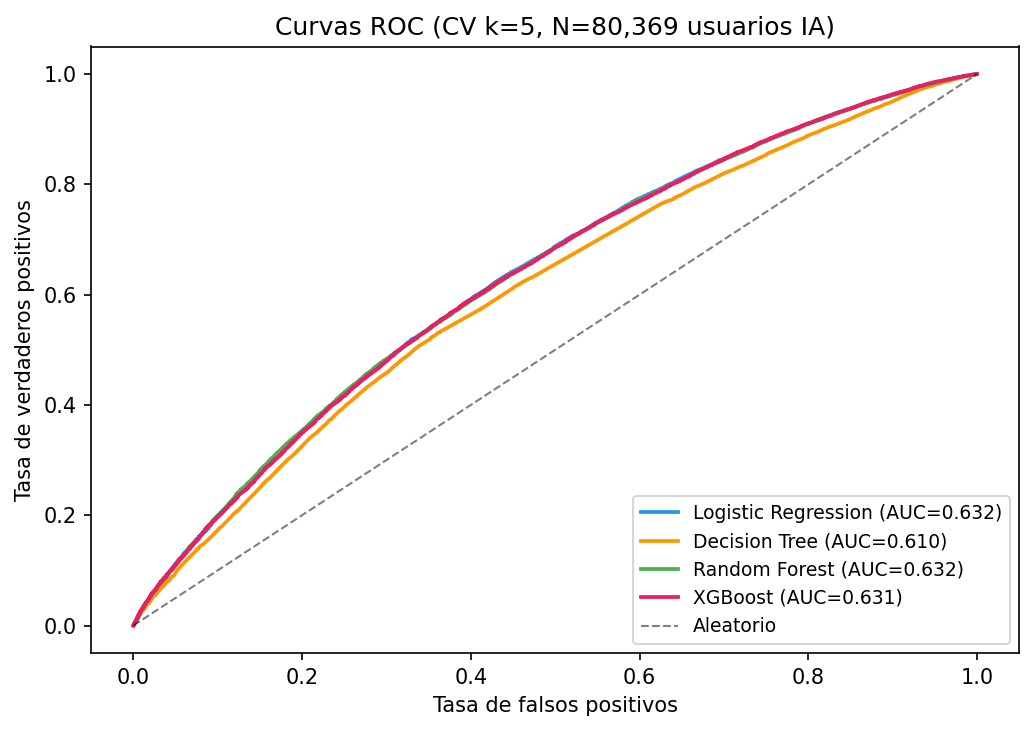

In [5]:
auc_oof = modelado.curvas_roc(models, X, y, cv)
display(Image(filename=str(ROOT / "outputs" / "modelos_curvas_roc.png")))

## 6. Comparación con todos los desarrolladores

Se entrena la misma regresión logística, con la misma validación cruzada, sobre todos los desarrolladores (155k) y sobre los usuarios de IA (80k).

In [6]:
X_full, y_full, label_full = auc_decision.cargar_dataset(restricted=False)
res_full = auc_decision.evaluar_logreg(X_full, y_full, label_full)

X_res, y_res, label_res = auc_decision.cargar_dataset(restricted=True)
res_res = auc_decision.evaluar_logreg(X_res, y_res, label_res)

comp = pd.DataFrame({
    "Métrica": ["N", "Prevalencia sin discrepancia", "ROC-AUC", "PR-AUC sin discrepancia", "PR-AUC con discrepancia"],
    "Todos los desarrolladores": [f"{res_full['n']:,}", f"{res_full['prevalence_target1']:.1%}",
                    f"{res_full['roc_auc']:.4f}", f"{res_full['pr_auc_pos']:.4f}", f"{res_full['pr_auc_neg']:.4f}"],
    "Usuarios de IA": [f"{res_res['n']:,}", f"{res_res['prevalence_target1']:.1%}",
                         f"{res_res['roc_auc']:.4f}", f"{res_res['pr_auc_pos']:.4f}", f"{res_res['pr_auc_neg']:.4f}"],
})
comp


Todos los desarrolladores (155k) (N=154,911, sin discrepancia: 40.7%)


  ROC-AUC = 0.7072
  PR-AUC (clase 1, 'Sin discrepancia') = 0.6039
  PR-AUC (clase 0, 'Con discrepancia uso-actitud') = 0.7672
  Matriz de confusión (filas: real 0 y 1; columnas: predicho 0 y 1):
     59063     32774
     21775     41299

Usuarios de IA (~80k) (N=80,369, sin discrepancia: 78.5%)


  ROC-AUC = 0.6319
  PR-AUC (clase 1, 'Sin discrepancia') = 0.8504
  PR-AUC (clase 0, 'Con discrepancia uso-actitud') = 0.3200
  Matriz de confusión (filas: real 0 y 1; columnas: predicho 0 y 1):
     10399      6896
     25813     37261


,Métrica,Todos los desarrolladores,Usuarios de IA
0,N,"154,911","80,369"
1,Prevalencia sin discrepancia,40.7%,78.5%
2,ROC-AUC,0.7072,0.6319
3,PR-AUC sin discrepancia,0.6039,0.8504
4,PR-AUC con discrepancia,0.7672,0.3200



Guardado outputs/comparacion_todos_vs_usuarios.png


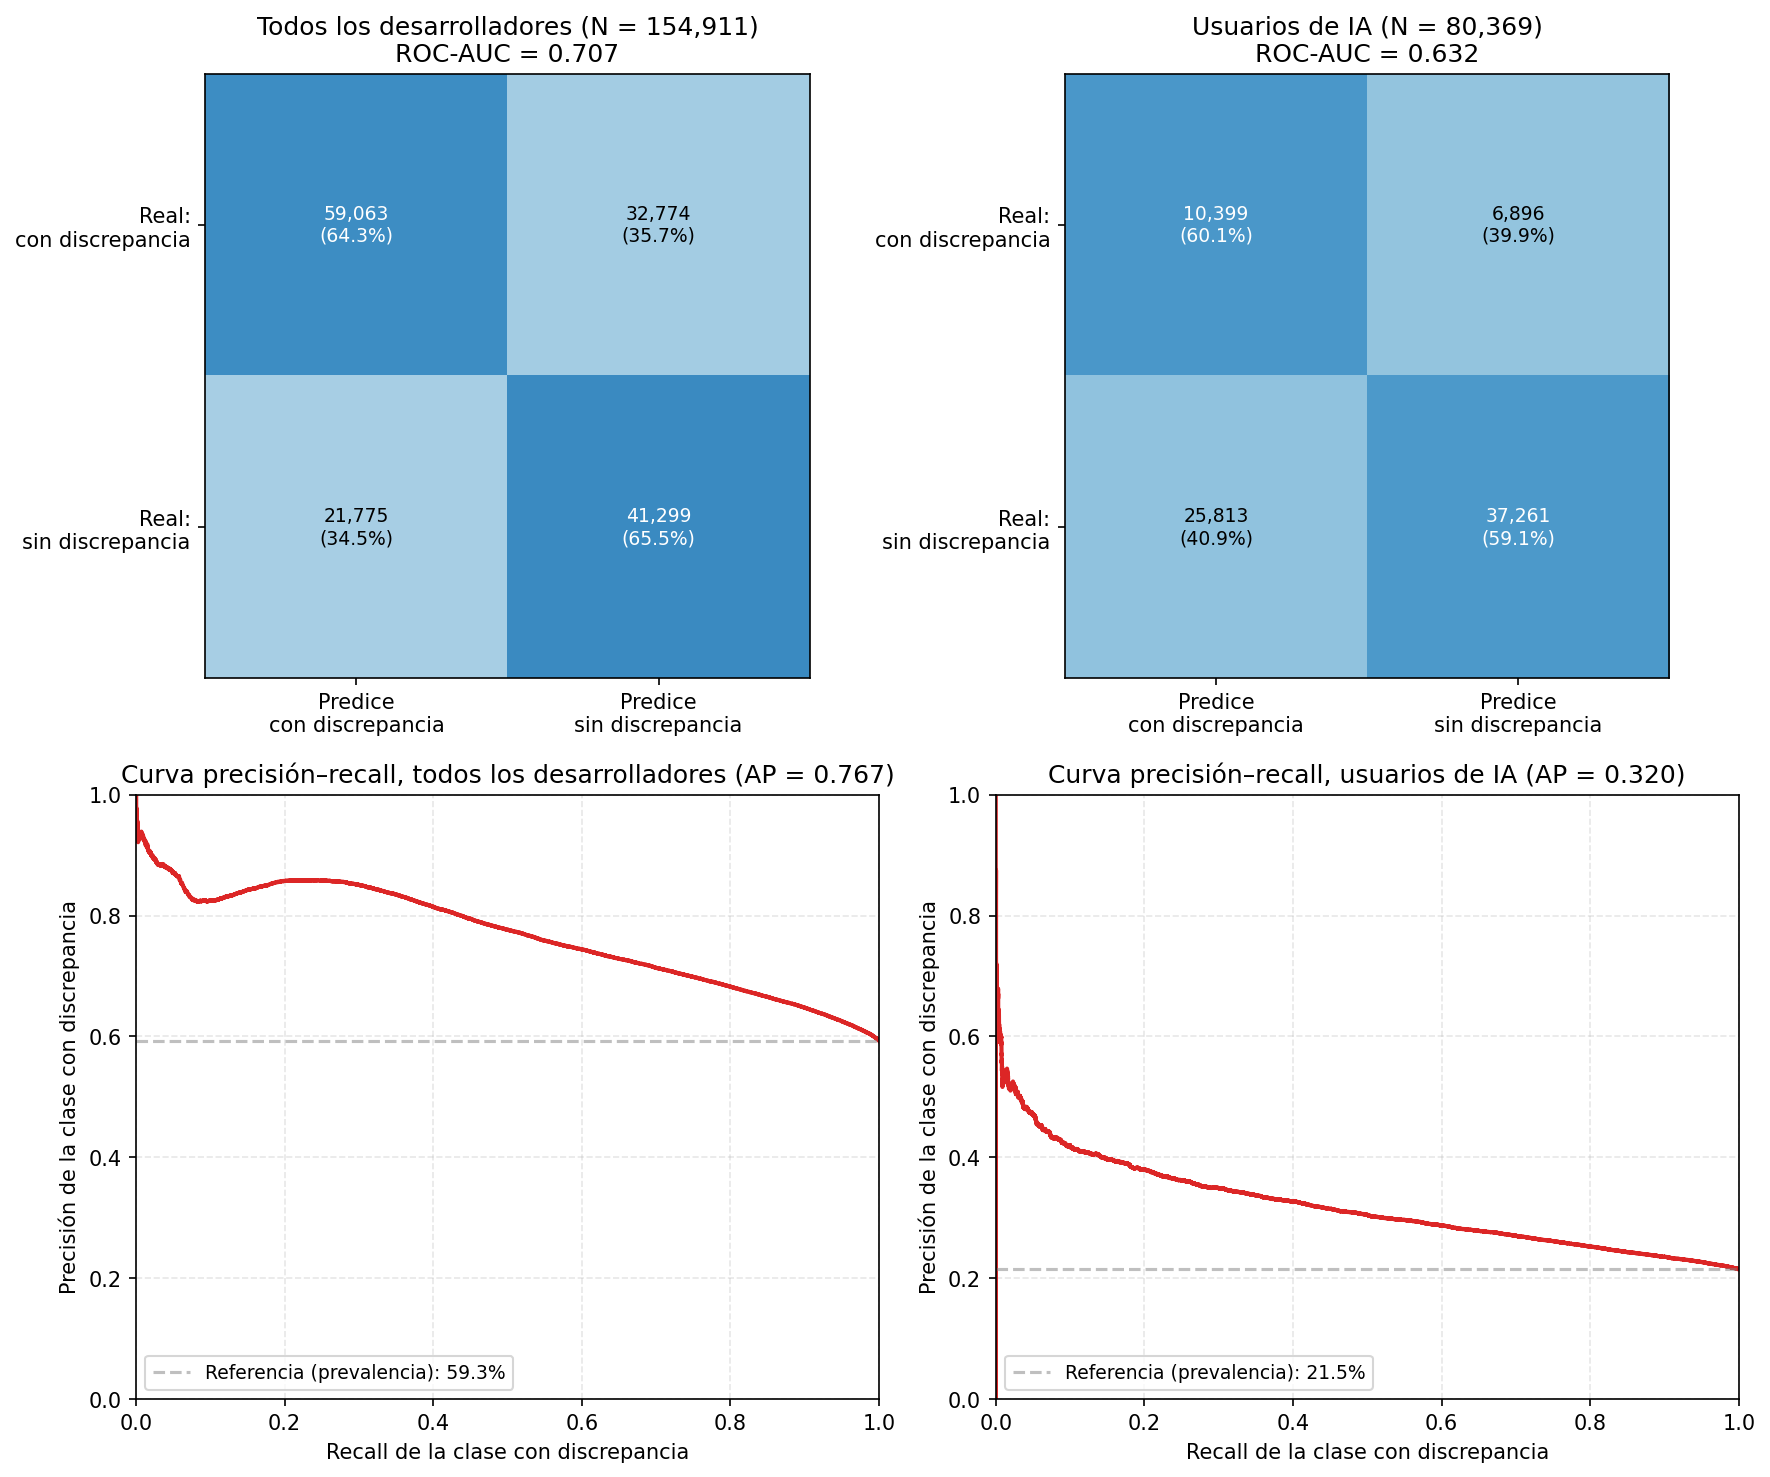

In [7]:
auc_decision.plot_comparison(res_full, res_res)
display(Image(filename=str(ROOT / "outputs" / "comparacion_todos_vs_usuarios.png")))

**Lectura.**
- El ROC-AUC baja de 0,707 (todos los desarrolladores) a 0,632 (usuarios de IA), 7,5 puntos. Con todos los datos, parte de la señal viene de separar a los usuarios de los no usuarios.
- El PR-AUC de la clase con discrepancia pasa de 0,767 a 0,320. Las referencias (la prevalencia de esa clase) son 59,3 % y 21,5 %, así que la ganancia sobre la referencia es de 17,4 y de 10,5 puntos.
- El ROC-AUC no depende de la prevalencia de las clases. La caída no se explica por el cambio de 40/60 a 78/22.
- Detalle en `docs/analisis/decision_drop_auc.md`.

## 7. SHAP global

In [8]:
df_results = pd.DataFrame(cv_results).T.sort_values("ROC-AUC", ascending=False)
best_name = df_results.index[0]
shap_name, top_features, X_bg, shap_values, fitted_model = modelado.shap_analysis(best_name, models, X, y)

print(f"\nModelo para SHAP: {shap_name}")
print("\n15 variables con mayor SHAP medio absoluto:")
top_features.sort_values(ascending=False).head(15).round(4)

Modelo para SHAP: Random Forest
  Entrenando con todos los datos... 

listo.


  shap_values: (1000, 98)

10 variables con mayor |SHAP| medio:
survey_year               0.043978
env_Visual_Studio_Code    0.021186
Region_EU                 0.012213
Region_ASIA               0.010919
env_Neovim                0.008722
plat_count                0.008393
lang_count                0.008323
env_count                 0.008303
Region_LATAM              0.007931
lang_C                    0.007713



Guardado outputs/shap_global.png
Guardado outputs/shap_barras.png

Modelo para SHAP: Random Forest

15 variables con mayor SHAP medio absoluto:


survey_year                        0.0440
env_Visual_Studio_Code             0.0212
Region_EU                          0.0122
Region_ASIA                        0.0109
env_Neovim                         0.0087
plat_count                         0.0084
lang_count                         0.0083
env_count                          0.0083
Region_LATAM                       0.0079
lang_C                             0.0077
lang_Rust                          0.0071
env_Jupyter_Notebook_JupyterLab    0.0060
plat_Firebase                      0.0056
YearsCode                          0.0050
lang_Python                        0.0047
dtype: float64

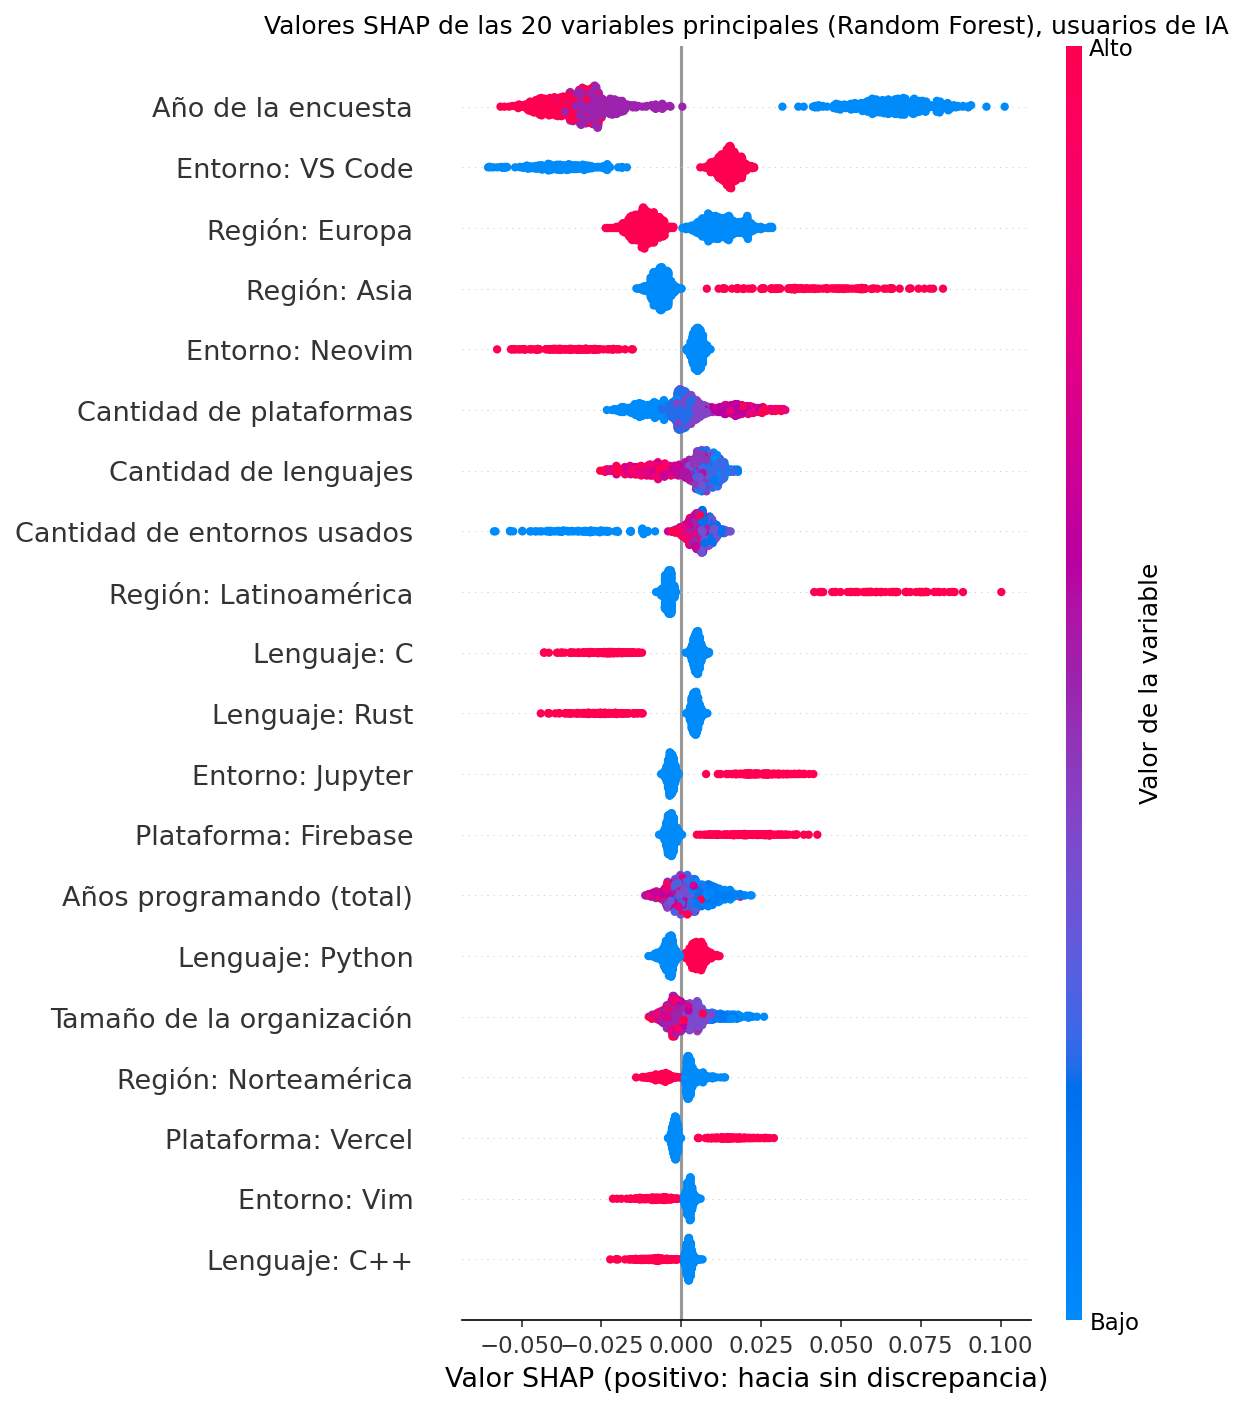

In [9]:
display(Image(filename=str(ROOT / "outputs" / "shap_global.png")))

**Lectura.** El año de la encuesta es la variable de mayor peso (0,044), seguido por el uso de VS Code (0,021), la región y la cantidad de herramientas que usa la persona. Los años programando quedan en el puesto 14. El año recoge el cambio del fenómeno en el tiempo, no describe a la persona.

## 8. SHAP en tres casos

In [10]:
cases = modelado.shap_local_cases(fitted_model, X_bg, shap_values, top_features)
for label, idx, prob in cases:
    print(f"  {label}: fila #{idx} de la muestra, probabilidad de discrepancia = {prob:.3f}")

Guardado outputs/shap_casos.png
  Caso A: mayor probabilidad de discrepancia: fila #933 de la muestra, probabilidad de discrepancia = 0.771
  Caso B: menor probabilidad de discrepancia: fila #832 de la muestra, probabilidad de discrepancia = 0.210
  Caso C: probabilidad cercana a 0,5: fila #477 de la muestra, probabilidad de discrepancia = 0.501


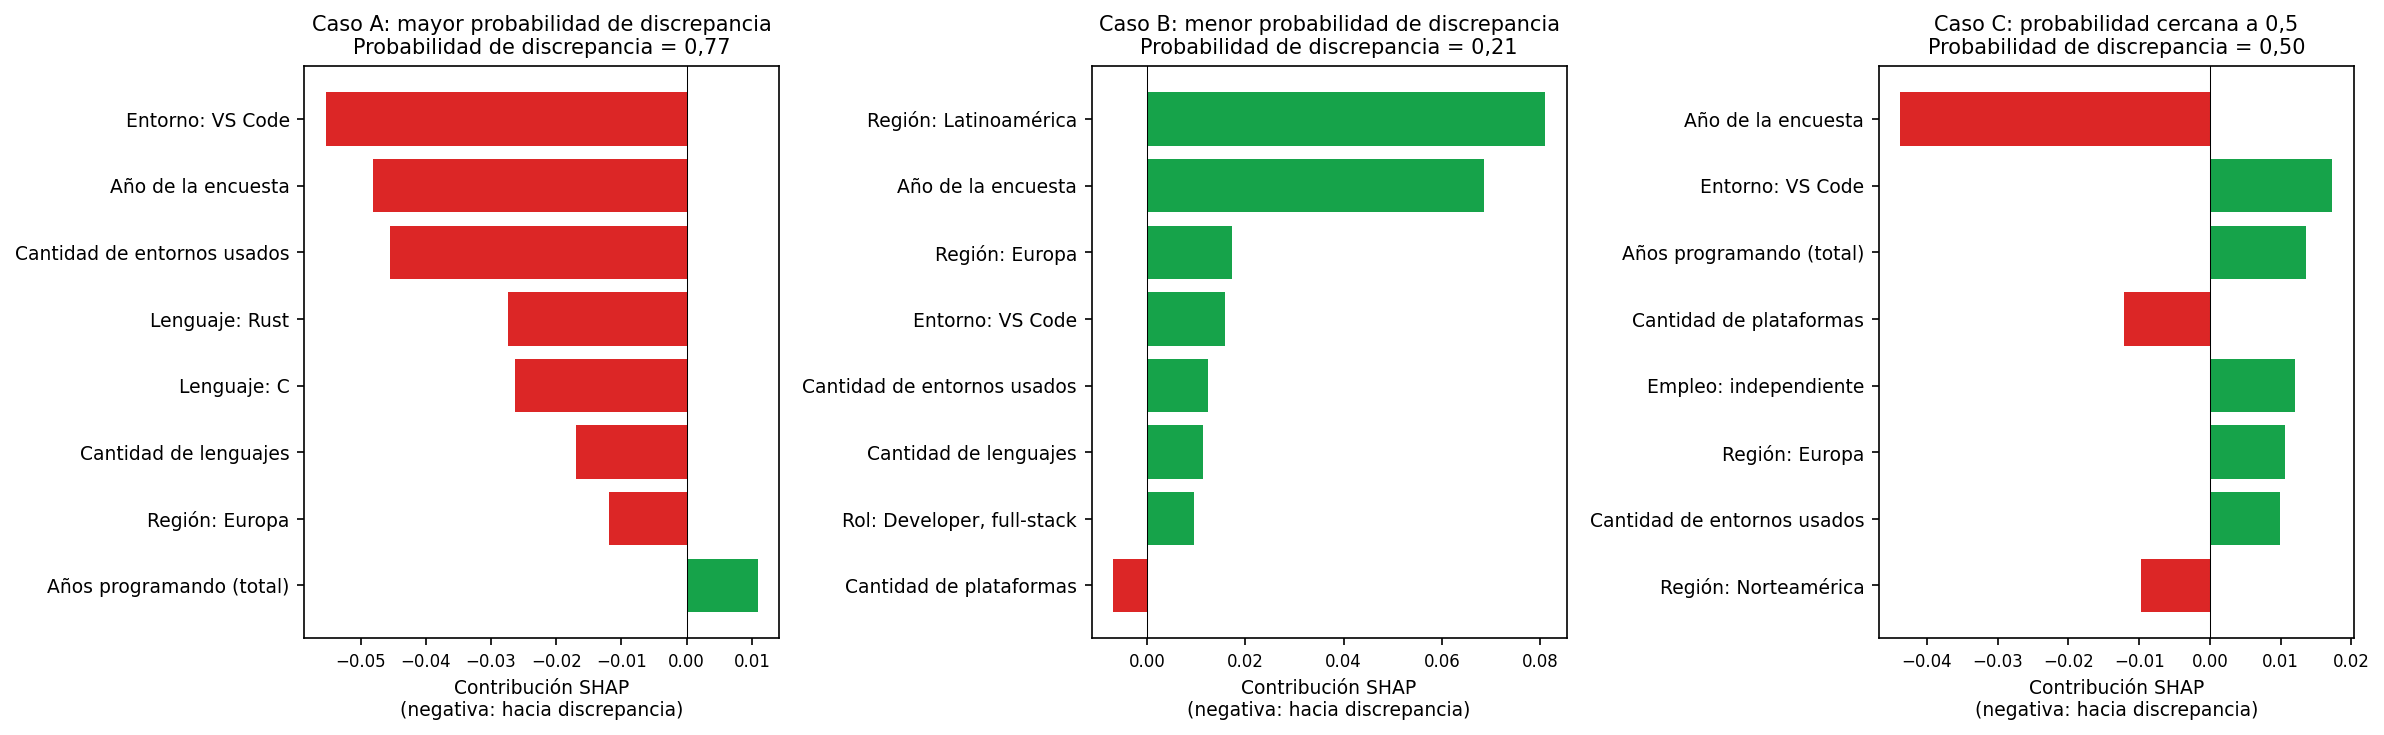

In [11]:
display(Image(filename=str(ROOT / "outputs" / "shap_casos.png")))

Los casos A y B son la observación de mayor y de menor probabilidad de discrepancia entre las 1.000 de la muestra. Son extremos, no perfiles típicos.

## 9. Dimensiones de Wang et al.

Cada variable se asigna a una dimensión según su nombre (ver el anexo A del trabajo).

In [12]:
wang_summary, df_wang = modelado.wang_mapping(top_features)
wang_summary.round(4)


SHAP por dimensión de Wang:
                  sum  count      mean
dim                                   
Ability      0.170470     74  0.002304
Integrity    0.057006     10  0.005701
Benevolence  0.039251     14  0.002804


Guardado outputs/shap_dimensiones_wang.png


,sum,count,mean
dim,,,
Ability,0.1705,74,0.0023
Integrity,0.0570,10,0.0057
Benevolence,0.0393,14,0.0028


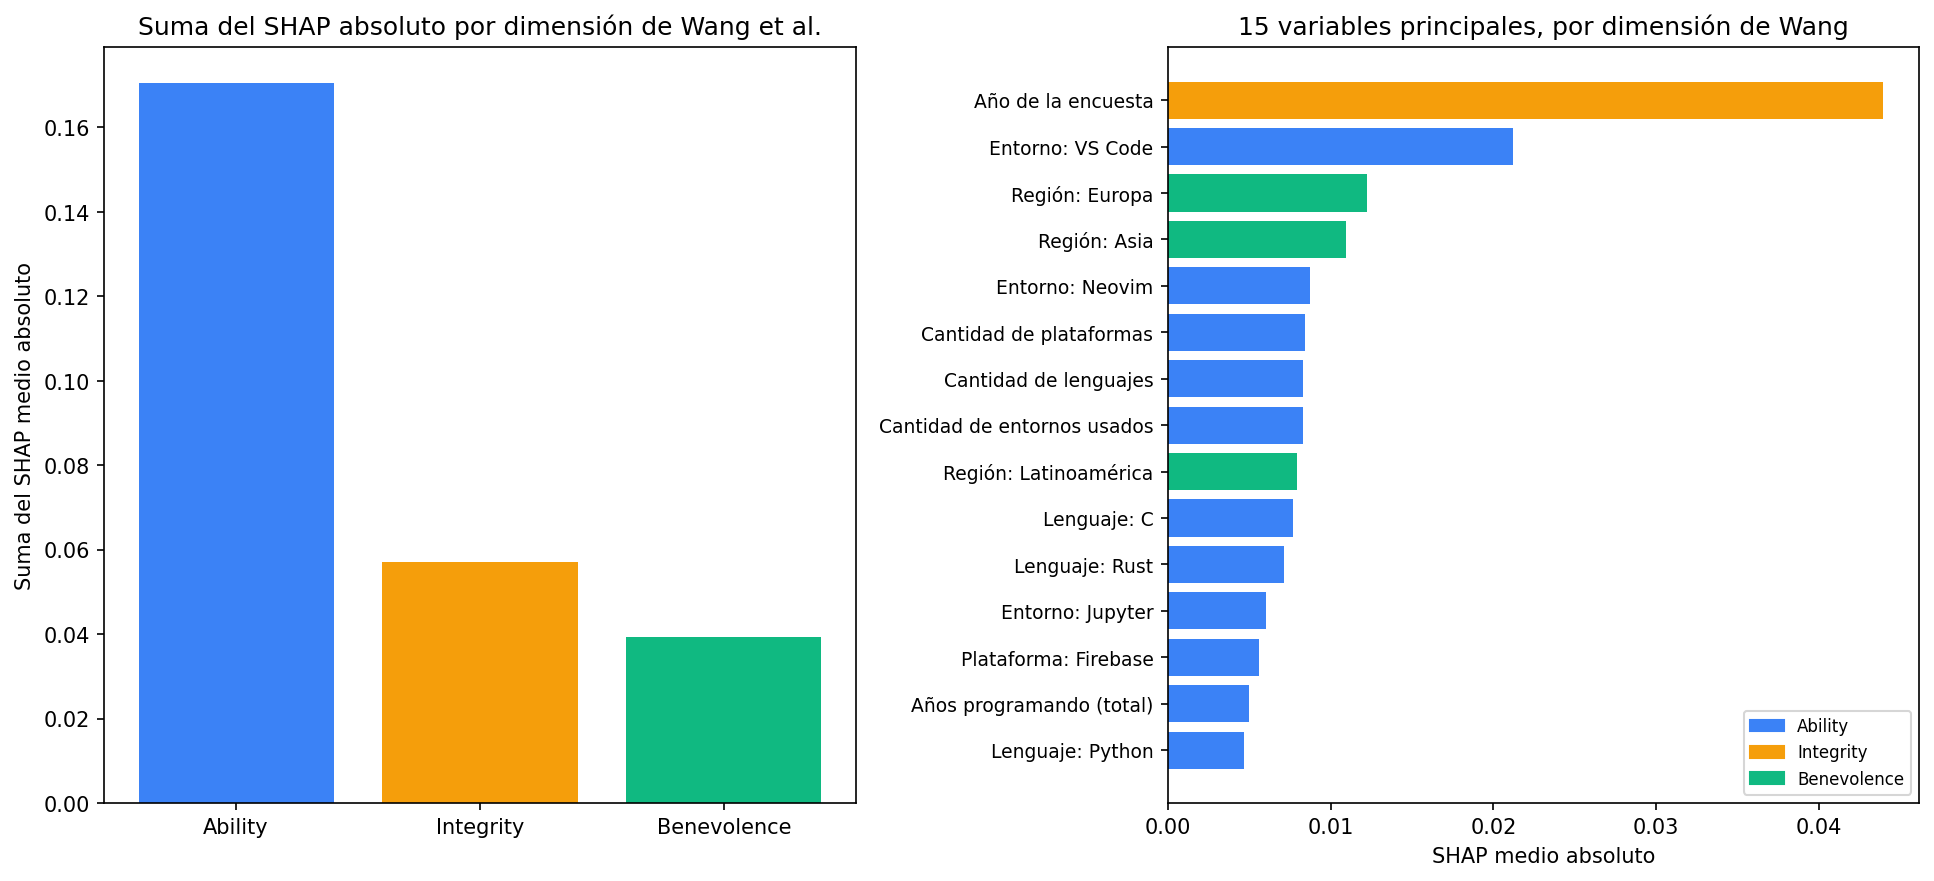

In [13]:
display(Image(filename=str(ROOT / "outputs" / "shap_dimensiones_wang.png")))

**Lectura.** Ability reúne el 63,9 % del SHAP total (74 variables), Integrity el 21,4 % (10) y Benevolence el 14,7 % (14). Ese reparto depende del número de variables de cada dimensión y del año de la encuesta, que se asignó a Integrity y aporta el 77,1 % de su peso. Por variable, sin el año, Benevolence aporta 0,0028, Ability 0,0023 e Integrity 0,0014.

## 10. Resumen

| Resultado | Valor |
|---|---|
| ROC-AUC de la regresión logística | 0,632 ± 0,006 |
| ROC-AUC del random forest | 0,632 |
| PR-AUC de la clase con discrepancia | 0,320 (referencia: 0,215) |
| Variable de mayor SHAP | año de la encuesta (0,044) |
| Ability, Integrity y Benevolence | 63,9 %, 21,4 % y 14,7 % del SHAP total |
| Umbral que maximiza F1 | 0,477 (precisión 0,28, recall 0,67) |

## 11. Análisis temporal

Se repite el análisis dentro de cada año y se mide el cambio entre años.

| Análisis | Descripción | Script |
|---|---|---|
| Descriptivo por año | Tasa de discrepancia, H1 y H2 por año | `scripts/temporal.py` |
| Dentro del año | Regresión logística y XGBoost entrenados y evaluados en el mismo año | `scripts/modelado_temporal.py` |
| Hacia adelante | Se entrena con años pasados y se evalúa en un año posterior | `scripts/modelado_temporal.py` |

Los tres usan las mismas 97 variables, que varían en los tres años, sin el año de la encuesta.

In [14]:
temporal = load_module("temporal", ROOT / "scripts" / "temporal.py")
mod_temp = load_module("modelado_temporal", ROOT / "scripts" / "modelado_temporal.py")

df_users = temporal.cargar()
feature_cols = mod_temp.common_features(df_users)
print(f"Usuarios de IA: {df_users.shape[0]:,} filas")
print(f"Variables comunes a los tres años (sin el año de la encuesta): {len(feature_cols)}")

Usuarios de IA: 80,369 filas
Variables comunes a los tres años (sin el año de la encuesta): 98


### Descriptivo por año

| Año | % con discrepancia | N | N con discrepancia |
|-----|---------------|---------|----------------|
| 2023 | 15,3 % | 29.697 | 4.553 |
| 2024 | 23,4 % | 29.638 | 6.943 |
| 2025 | 27,6 % | 21.034 | 5.799 |
| Los tres años | 21,5 % | 80.369 | 17.295 |

La tasa sube 8,1 puntos de 2023 a 2024 y 4,1 de 2024 a 2025. La diferencia por años programando es de +1,1, +2,0 y +8,2 puntos. El orden de los roles cambia entre años.

  H1 global: creciente (de 18.4% a 23.4%, diferencia +5.0 puntos)
  H1 2023: no creciente (de 15.2% a 16.3%, diferencia +1.1 puntos)
  H1 2024: no creciente (de 22.8% a 24.8%, diferencia +2.0 puntos)
  H1 2025: creciente (de 20.0% a 28.2%, diferencia +8.2 puntos)


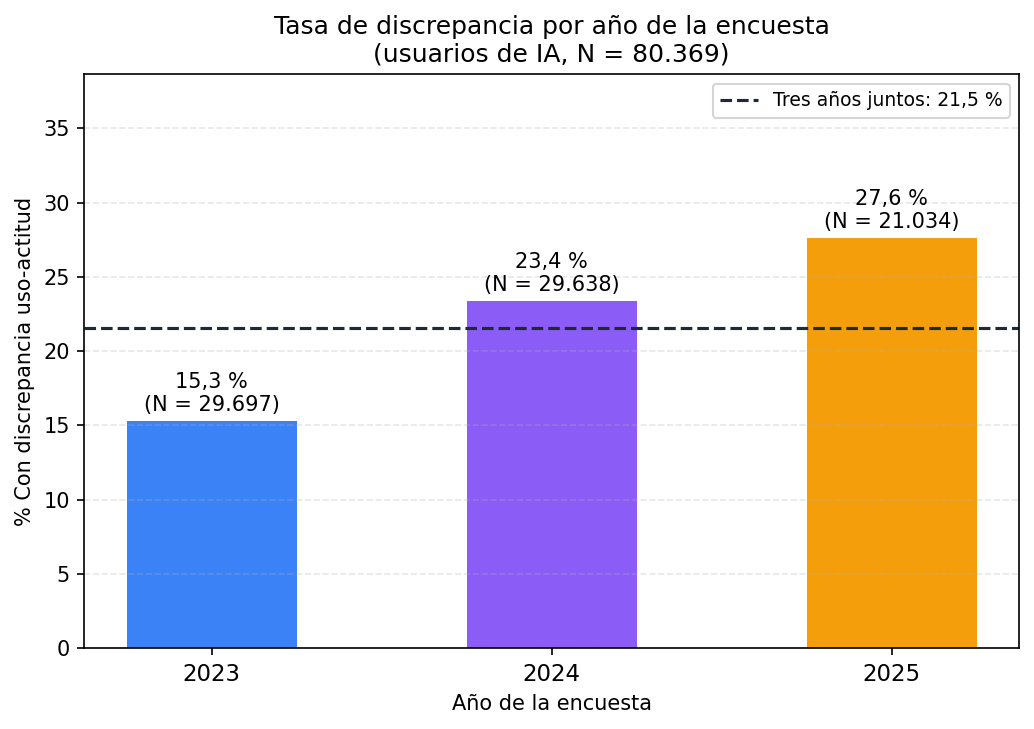

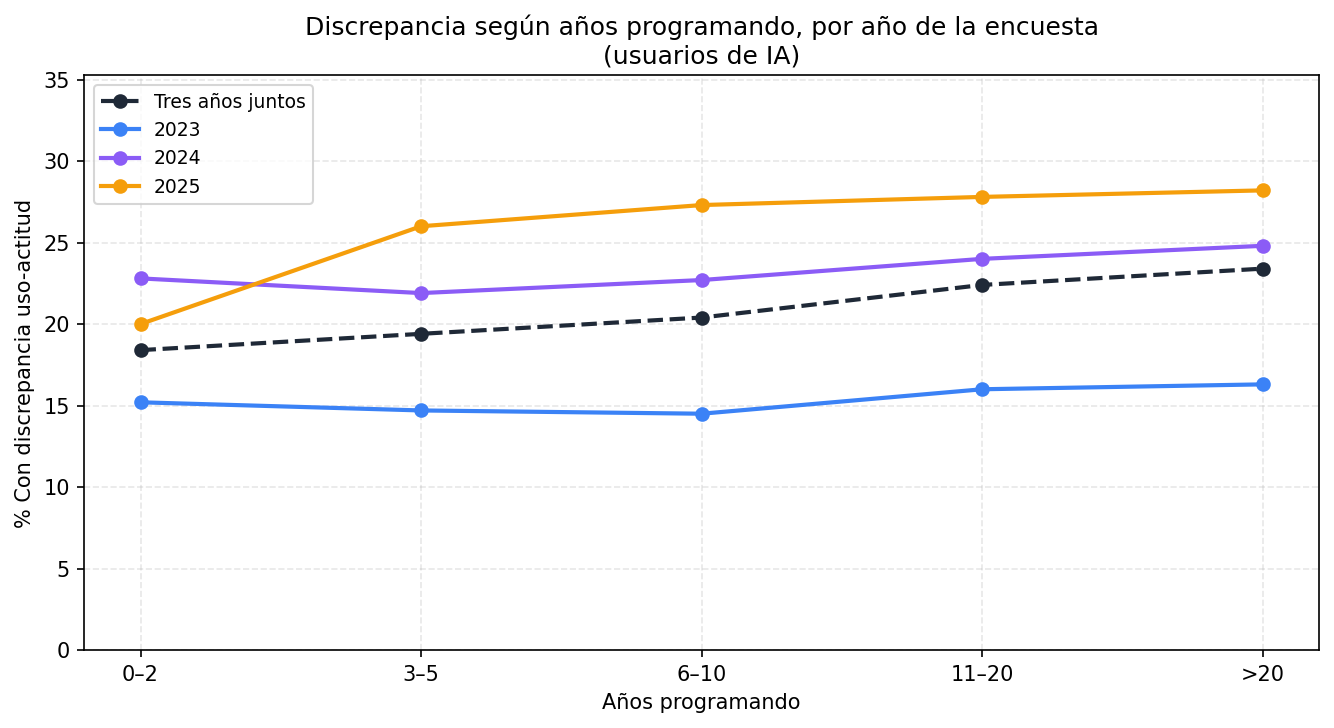

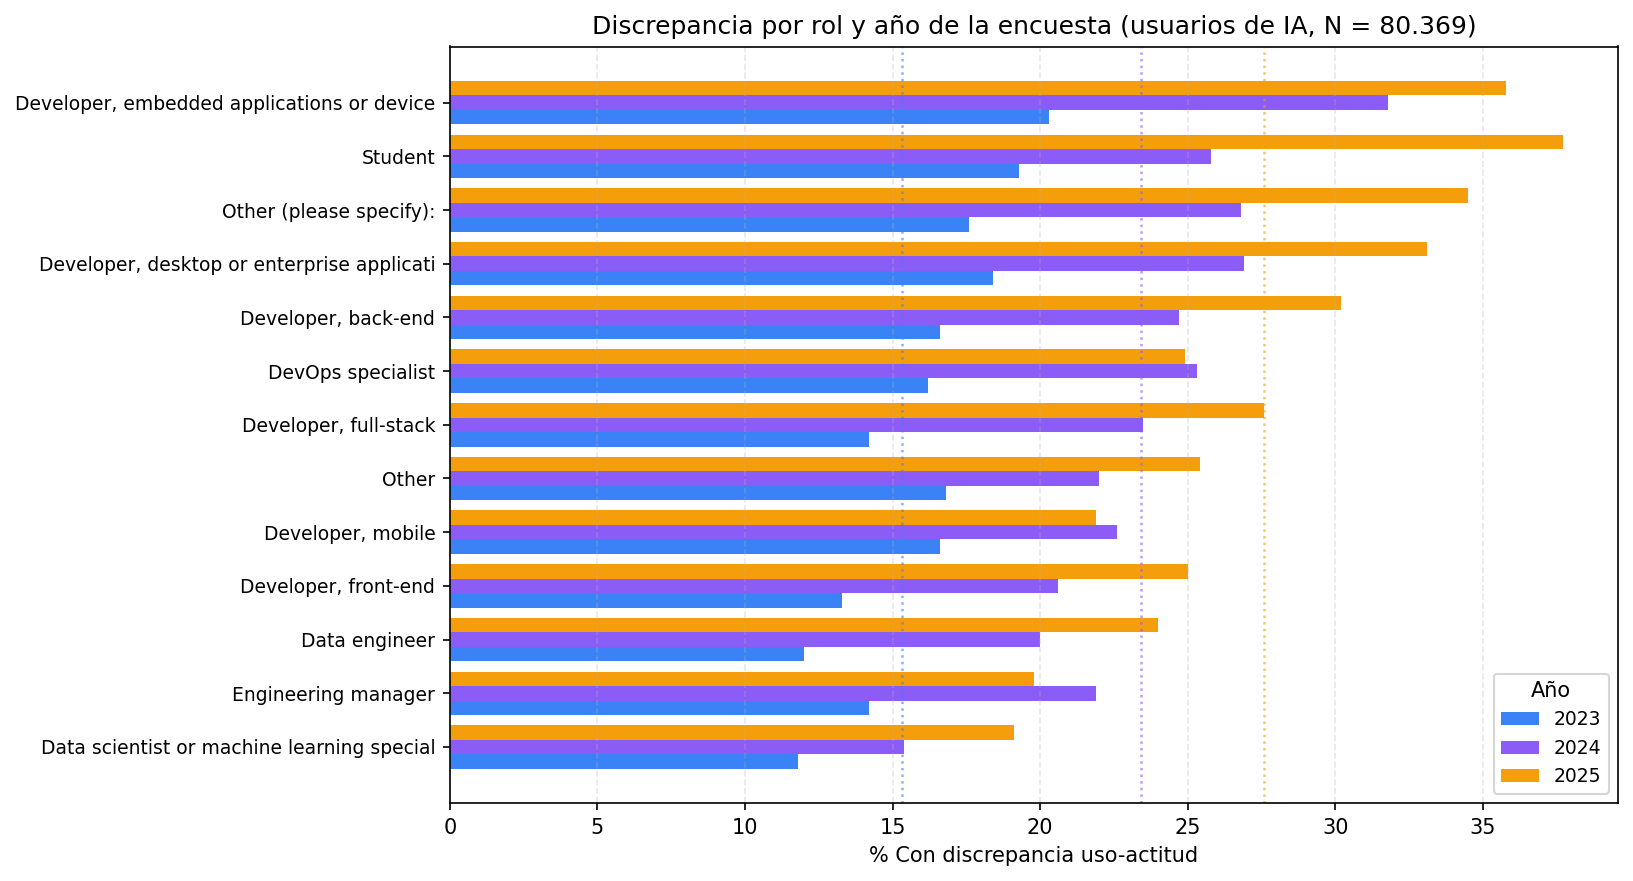

In [15]:
tabla_base, fig_base = temporal.tasa_base_por_anio(df_users)
tabla_h1, fig_h1 = temporal.h1_temporal_usuarios(df_users)
tabla_h2, fig_h2 = temporal.h2_temporal_usuarios(df_users)

for fig, nombre in [(fig_base, "temporal_tasa_discrepancia.png"), (fig_h1, "temporal_experiencia.png"), (fig_h2, "temporal_rol.png")]:
    fig.savefig(ROOT / "outputs" / nombre, dpi=150, bbox_inches="tight")
    display(Image(filename=str(ROOT / "outputs" / nombre)))

### Modelos dentro de cada año

| Condición | ROC-AUC | PR-AUC | N |
|---|---|---|---|
| Años juntos, con el año de la encuesta | 0,6319 | 0,3200 | 80.369 |
| Años juntos, sin el año de la encuesta | 0,6118 | 0,2976 | 80.369 |
| Dentro del año 2023 | 0,5792 | 0,1925 | 29.697 |
| Dentro del año 2024 | 0,6011 | 0,3098 | 29.638 |
| Dentro del año 2025 | 0,6323 | 0,3840 | 21.034 |

El ROC-AUC dentro del año sube de 0,579 a 0,632, y la prevalencia de la clase con discrepancia sube de 15,3 % a 27,6 %. El año de la encuesta aporta 0,020 de ROC-AUC al modelo con los años juntos.

**Coeficientes.** Cambian de signo 43 de las 97 variables, pero casi todas tienen coeficientes cercanos a cero. Tres lecturas se sostienen:
- La cantidad de bases de datos pasa de +0,08 en 2023 y +0,02 en 2024 a +0,28 en 2025: más bases de datos se asocia con menos discrepancia, sobre todo en 2025.
- La región Asia sube de +0,02 a +0,11 y +0,13: la discrepancia en Asia es cada vez más baja que en el resto.
- Los coeficientes de la experiencia crecen en 2025 (experiencia laboral +0,22, años programando −0,16), pero las dos variables están correlacionadas (0,88 en 2025) y sus coeficientes se compensan. No se leen por separado.

  Años juntos, con survey_year             ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=80,369)


  Años juntos, sin survey_year             ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=80,369)


  Regresión logística, 2023                ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=29,697)


  Regresión logística, 2024                ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=29,638)


  Regresión logística, 2025                ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=21,034)
  XGBoost por año (con menos filas por año puede sobreajustar)


...

  XGBoost, 2024                            ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=29,638)


  XGBoost, 2025                            ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N=21,034)


  SHAP 2023: top = discrepancia (0.2543)


  SHAP 2024: top = discrepancia (0.2515)


  SHAP 2025: top = discrepancia (0.2594)


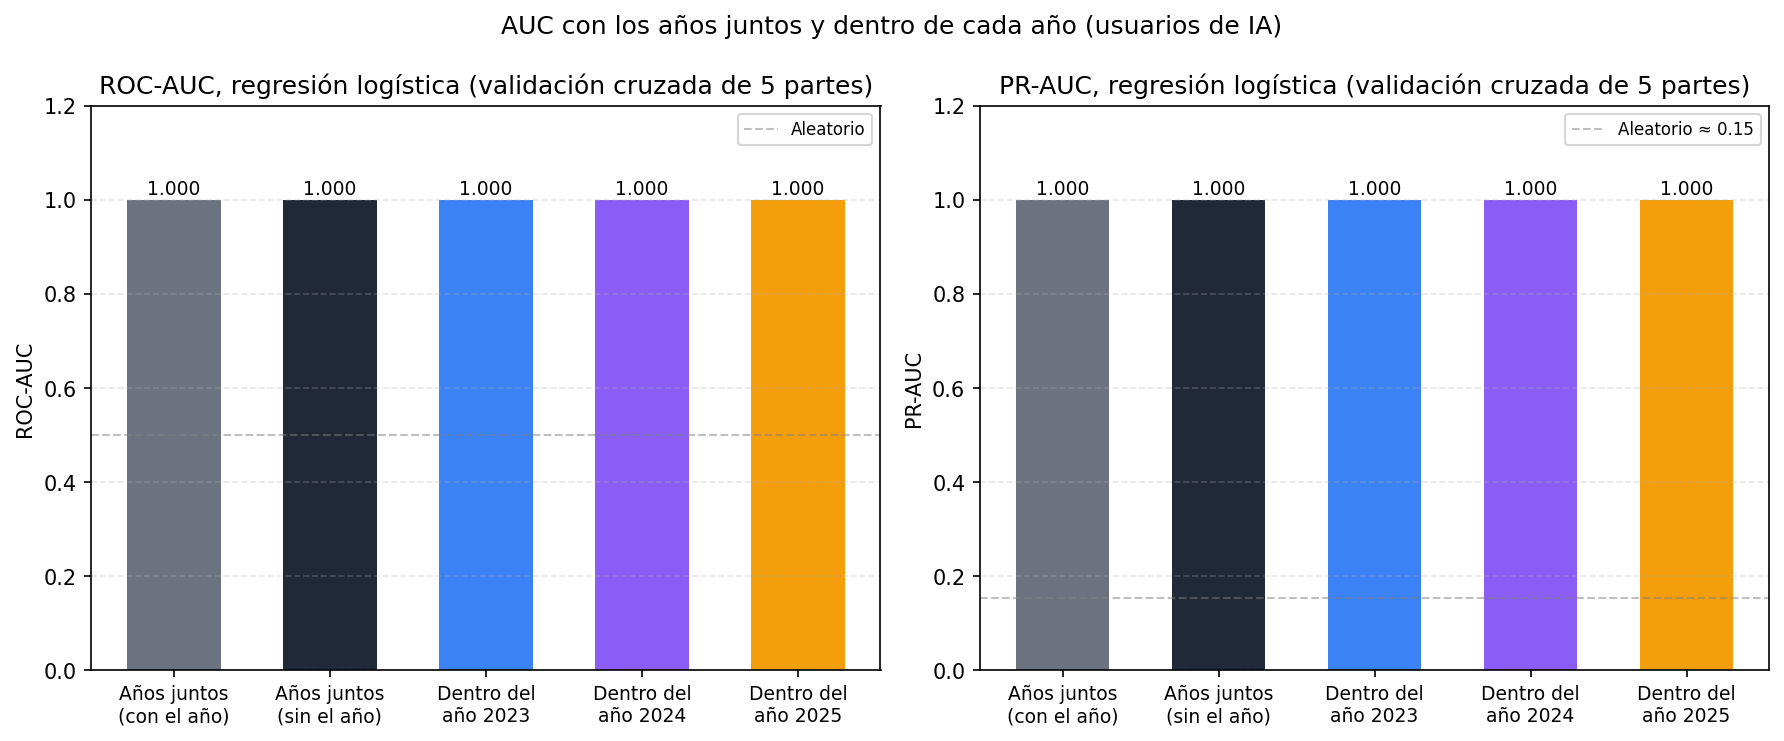

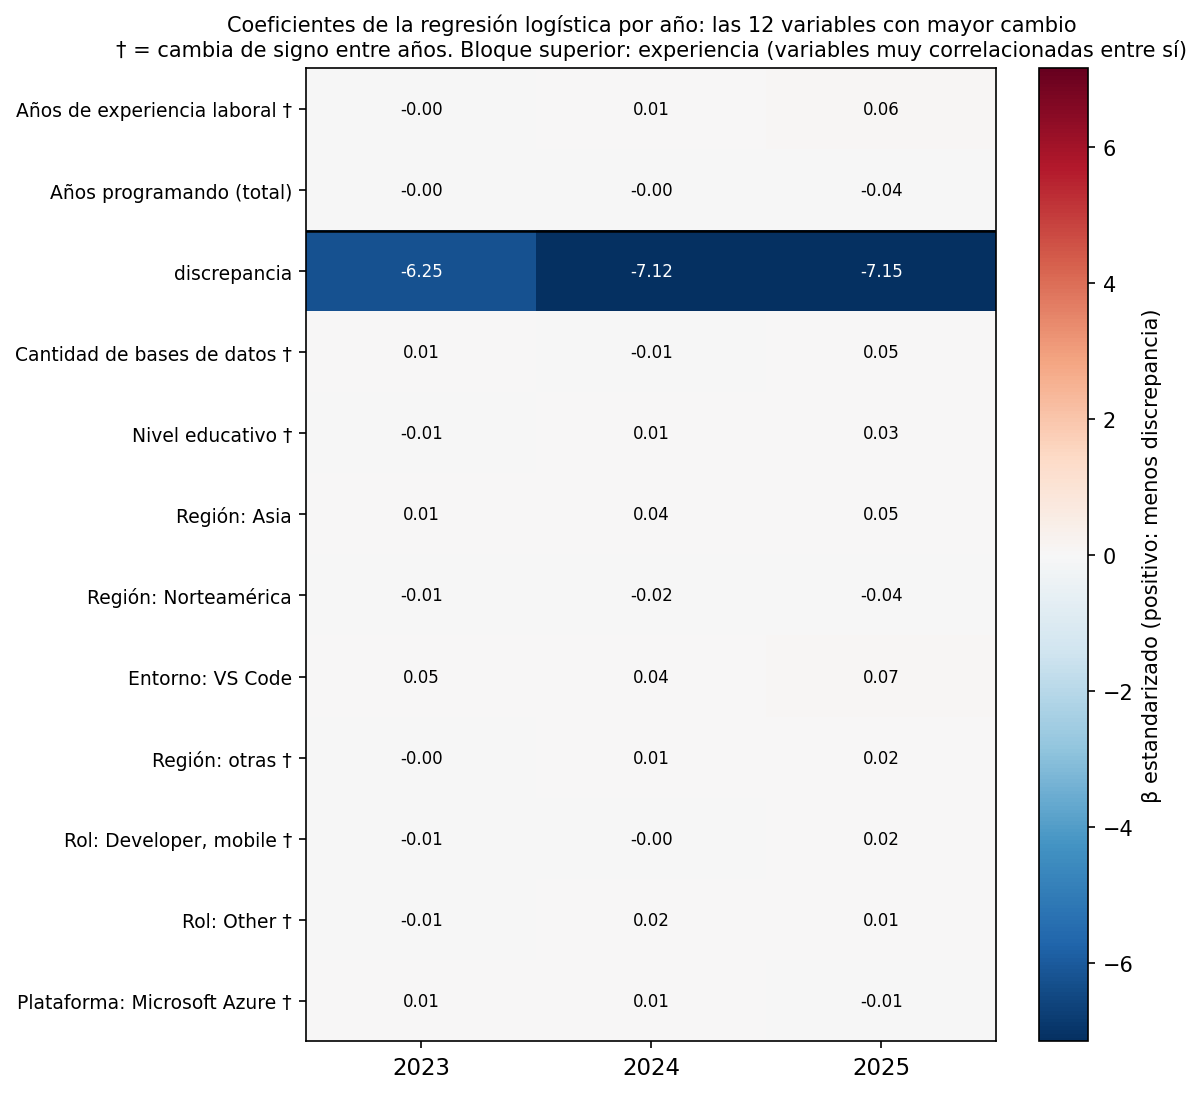

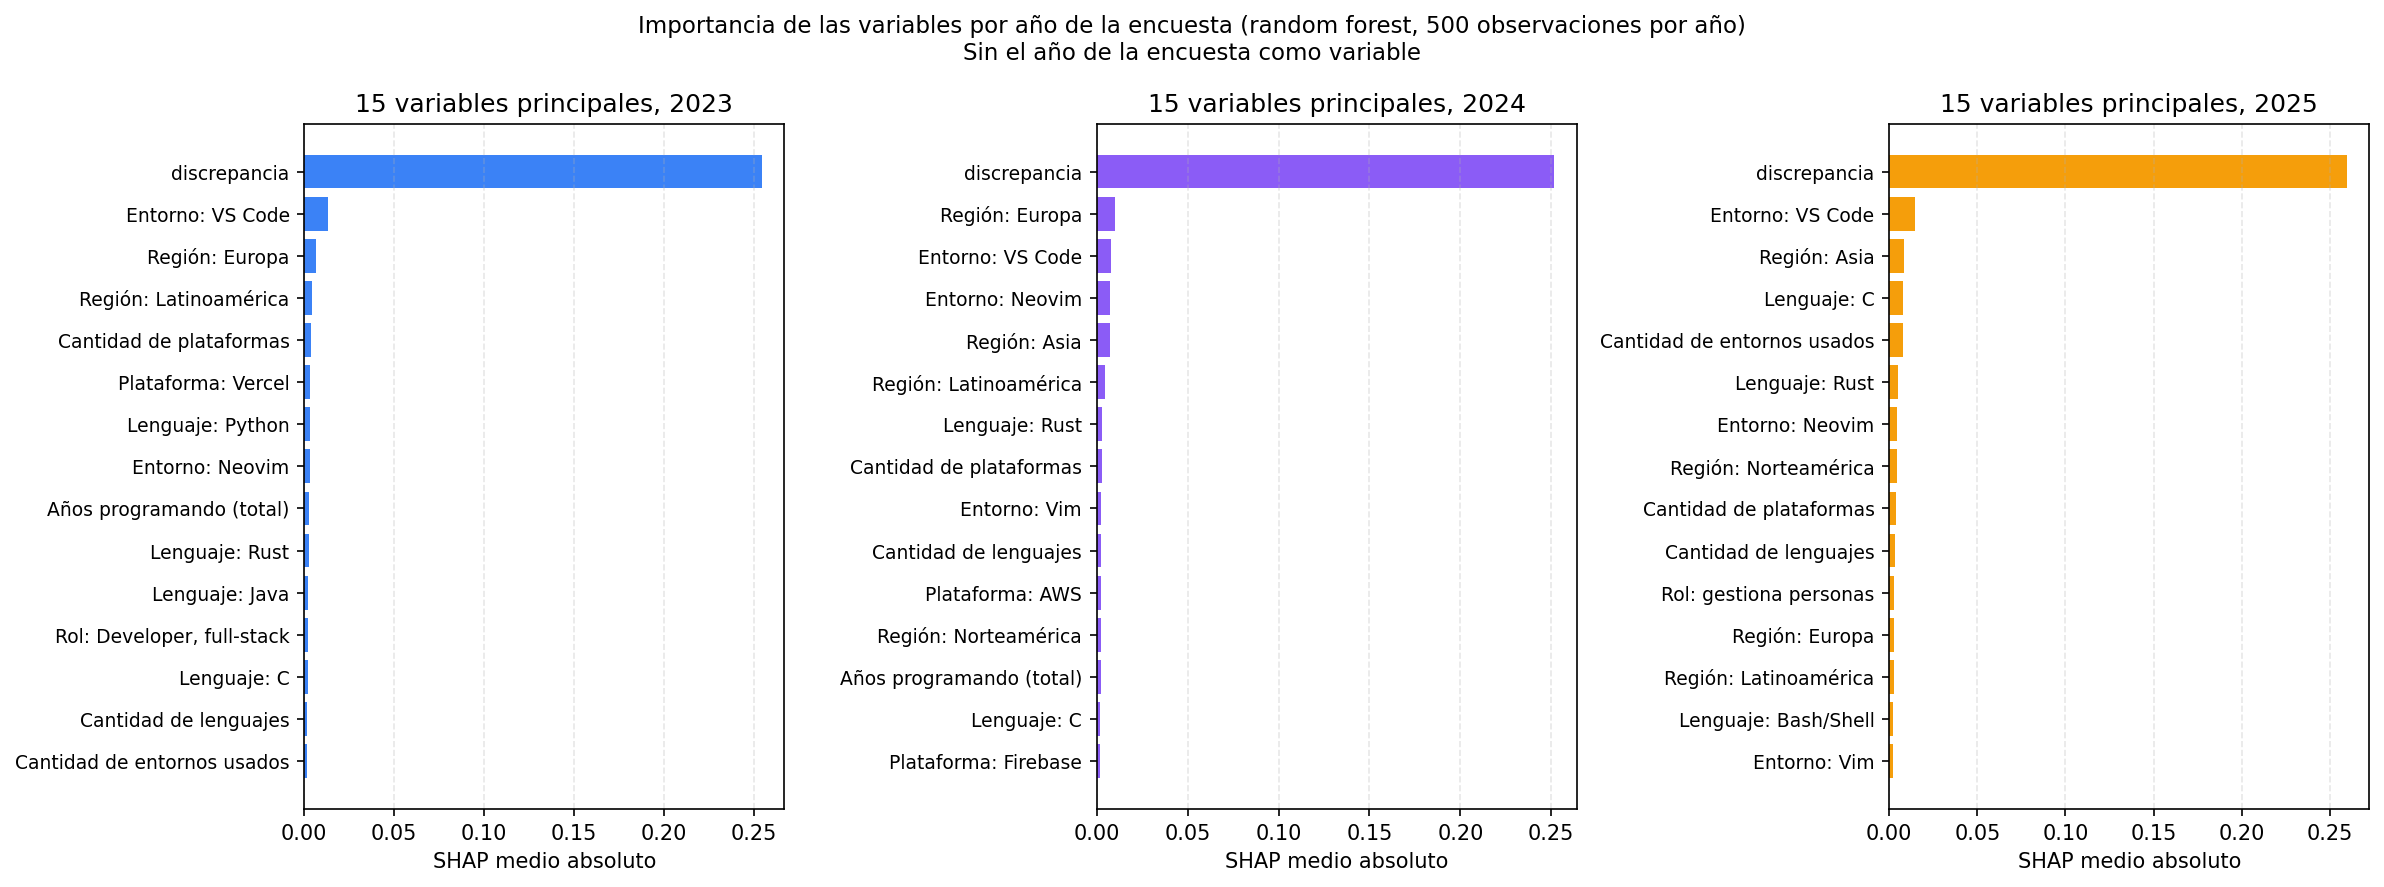

In [16]:
auc_results = mod_temp.comparar_auc(df_users, feature_cols)
xgb_results = mod_temp.xgb_check_por_anio(df_users, feature_cols)
tabla_coef = mod_temp.coeficientes_por_anio(df_users, feature_cols)
shap_results = mod_temp.shap_rf_por_anio(df_users, feature_cols)

figuras = [
    (mod_temp.figura_auc_comparison(auc_results), "temporal_auc.png"),
    (mod_temp.figura_coef_heatmap(tabla_coef, n_top=12), "temporal_coeficientes.png"),
    (mod_temp.figura_shap_por_anio(shap_results, n_top=15), "temporal_shap_por_anio.png"),
]
for fig, nombre in figuras:
    fig.savefig(ROOT / "outputs" / nombre, dpi=150, bbox_inches="tight")
    display(Image(filename=str(ROOT / "outputs" / nombre)))

### Validación hacia adelante

| Esquema | ROC-AUC hacia adelante | ROC-AUC dentro del año | Diferencia | PR-AUC |
|---|---|---|---|---|
| 2023 → 2024 | 0,5818 | 0,6011 | −1,9 puntos | 0,2978 |
| 2024 → 2025 | 0,6226 | 0,6323 | −1,0 puntos | 0,3764 |
| 2023 y 2024 → 2025 | 0,6219 | 0,6323 | −1,0 puntos | 0,3769 |

Hay una pérdida medible al evaluar en un año posterior, es decir *concept drift*, pero es chica y no crece de una transición a la siguiente. Entrenar con dos años en lugar de uno no mejora el resultado.

  Entrena con 2023, evalúa en 2024         ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N_train=29,697  N_test=29,638)


  Entrena con 2024, evalúa en 2025         ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N_train=29,638  N_test=21,034)


  Entrena con 2023+2024, evalúa en 2025    ROC-AUC=1.0000  PR-AUC(min)=1.0000  (N_train=59,335  N_test=21,034)


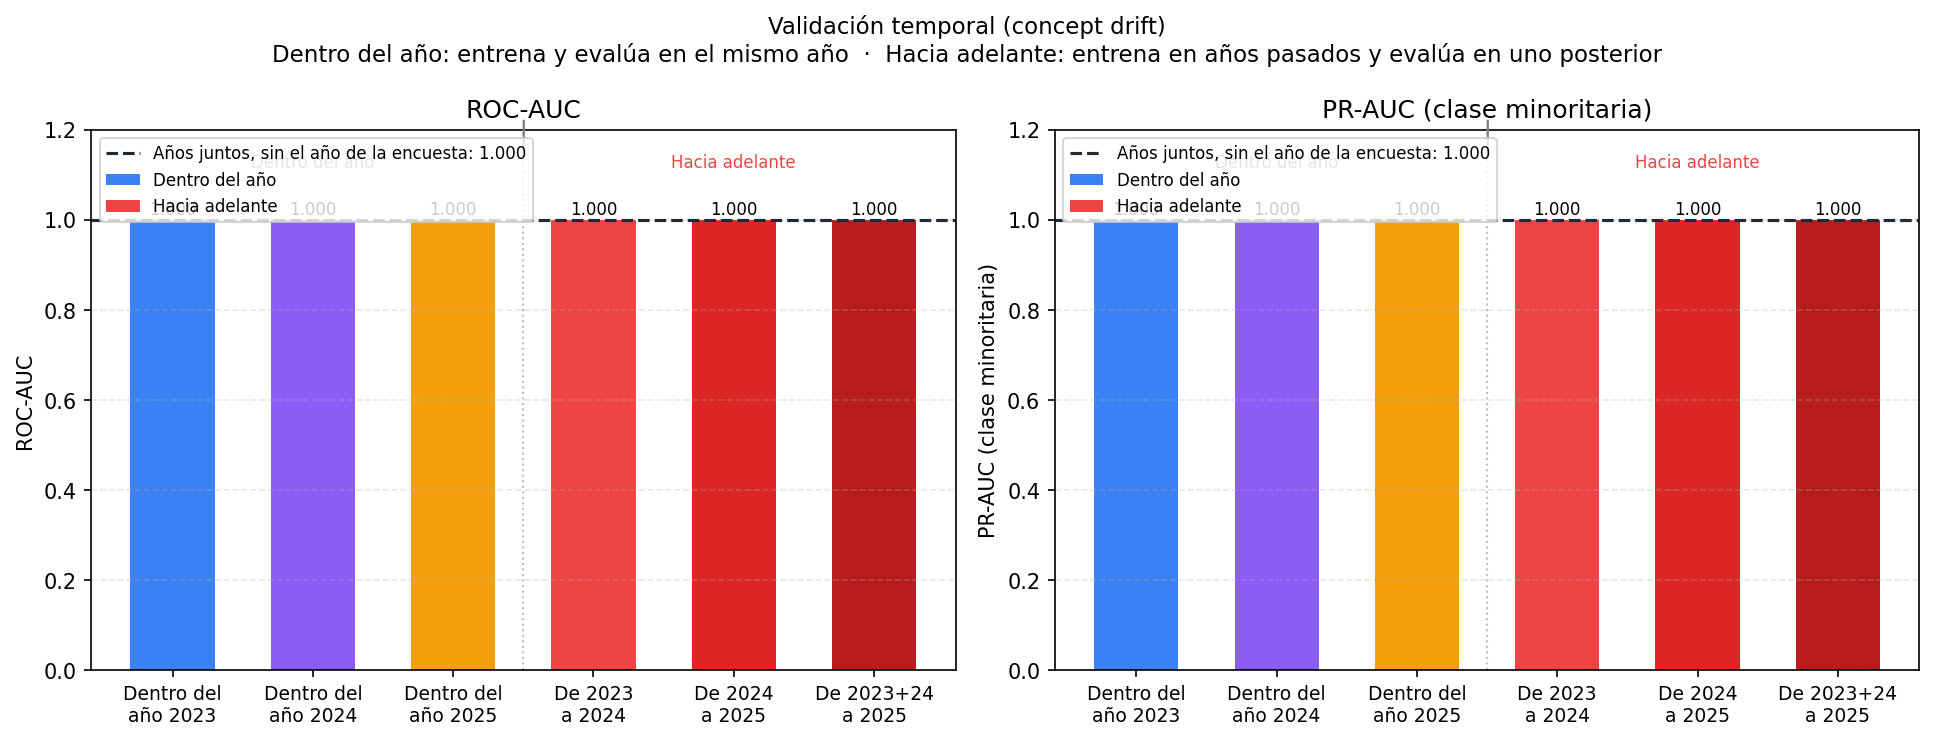

In [17]:
forward_results = {
    "fwd_23_24": mod_temp.evaluar_forward(df_users, feature_cols, [2023], 2024),
    "fwd_24_25": mod_temp.evaluar_forward(df_users, feature_cols, [2024], 2025),
    "fwd_2324_25": mod_temp.evaluar_forward(df_users, feature_cols, [2023, 2024], 2025),
}
fig_val = mod_temp.figura_validacion_temporal(auc_results, forward_results, auc_results["pooled_sin_year"]["roc_auc"])
fig_val.savefig(ROOT / "outputs" / "temporal_validacion.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(ROOT / "outputs" / "temporal_validacion.png")))

### Resumen

El ROC-AUC de 0,63 con los años juntos mezcla tres momentos del fenómeno. Dentro de cada año la señal es más débil en 2023 (0,579) y más fuerte en 2025 (0,632). Sin el año de la encuesta, juntar los años da 0,612. Al evaluar en un año posterior se pierde entre 1,0 y 1,9 puntos.

Más detalle en `docs/analisis/resultados_temporal_usuarios.md` y `docs/analisis/resultados_modelado_temporal.md`.